# Setting phage life mode tables

In [1]:
import pandas as pd

dataset2 = pd.read_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/01_process_votus/tables/rel_abund/votus_dataset2_TMM_rel_abund.tsv', sep='\t')
dataset2 = dataset2['contig_id'].tolist()
dataset2

['AP1_NODE_1019_length_28805_cov_4.940442',
 'AP1_NODE_1026_length_28694_cov_1.324710',
 'AP1_NODE_10_length_320914_cov_6.491204',
 'AP1_NODE_114_length_107093_cov_3.309715',
 'AP1_NODE_1255_length_25433_cov_16.962025',
 'AP1_NODE_1400_length_23805_cov_8.183799',
 'AP1_NODE_1422_length_23637_cov_2.675202',
 'AP1_NODE_1426_length_23605_cov_7.618324',
 'AP1_NODE_159_length_92405_cov_3.227497',
 'AP1_NODE_1661_length_21770_cov_8.340249',
 'AP1_NODE_1701_length_21519_cov_3.075729',
 'AP1_NODE_172_length_87936_cov_2.467071',
 'AP1_NODE_202_length_77610_cov_2.540467',
 'AP1_NODE_220_length_72284_cov_40.156298',
 'AP1_NODE_2381_length_17703_cov_2.970642',
 'AP1_NODE_2440_length_17401_cov_18.193702',
 'AP1_NODE_2486_length_17240_cov_3.289955',
 'AP1_NODE_2561_length_16936_cov_2.319591',
 'AP1_NODE_261_length_64903_cov_2.165231',
 'AP1_NODE_2719_length_16335_cov_2.231861',
 'AP1_NODE_3041_length_15343_cov_1.304022',
 'AP1_NODE_304_length_60393_cov_2.701391',
 'AP1_NODE_314_length_59746_cov_3.39

In [2]:
from Bio import SeqIO

vibrant_results = '/MP_Data/Dados_David/viral_analysis/post_processing/votus_definition/vibrant/VIBRANT_bac_ncldv_virophage_votus/VIBRANT_phages_bac_ncldv_virophage_votus'

lysogenic = [record.id for record in SeqIO.parse(f'{vibrant_results}/bac_ncldv_virophage_votus.phages_lysogenic.fna','fasta')]
lytic = [record.id for record in SeqIO.parse(f'{vibrant_results}/bac_ncldv_virophage_votus.phages_lytic.fna','fasta')]


vibrant_df = pd.DataFrame({
    'votus':lysogenic,
    'life_mode':'Lysogenic'
}) 
lytic_df = pd.DataFrame({
    'votus':lytic,
    'life_mode':'Litic'
}) 

vibrant_df = pd.concat([vibrant_df,lytic_df])
vibrant_df

,votus,life_mode
0,BP4_NODE_3199_length_11954_cov_14.458694,Lysogenic
1,MP1_NODE_384_length_53716_cov_4.046670,Lysogenic
2,MP2_NODE_114_length_74850_cov_3.294247,Lysogenic
3,MP2_NODE_114_length_74850_cov_3.294247,Lysogenic
4,AP5_NODE_3693_length_11405_cov_1.095052,Lysogenic
...,...,...
6038,AP2_NODE_4827_length_12747_cov_5.337876,Litic
6039,AP2_NODE_4681_length_12984_cov_1.909932,Litic
6040,BP4_NODE_2324_length_14417_cov_47.165019,Litic
6041,MP4_NODE_938_length_22799_cov_1.574718,Litic


# Removing NCLDVs and virophages

In [3]:
ncldv_list = [record.id for record in SeqIO.parse("/MP_Data/Dados_David/viral_analysis/post_processing/ncldv_virophage_plv_check/NCLDVs_phylogeny/putative_ncldvs/putative_ncldvs.fasta",'fasta')]
virophage_list = [record.id for record in SeqIO.parse("/MP_Data/Dados_David/viral_analysis/post_processing/ncldv_virophage_plv_check/virophage_phylogeny/putative_virophages/putative_virophages.fasta","fasta")]

drop_list = ncldv_list + virophage_list

vibrant_df = vibrant_df[~vibrant_df['votus'].isin(drop_list)]
vibrant_df

,votus,life_mode
0,BP4_NODE_3199_length_11954_cov_14.458694,Lysogenic
1,MP1_NODE_384_length_53716_cov_4.046670,Lysogenic
4,AP5_NODE_3693_length_11405_cov_1.095052,Lysogenic
5,MP1_NODE_4424_length_11710_cov_18.113097,Lysogenic
6,PP5_NODE_2079_length_10783_cov_0.853322,Lysogenic
...,...,...
6038,AP2_NODE_4827_length_12747_cov_5.337876,Litic
6039,AP2_NODE_4681_length_12984_cov_1.909932,Litic
6040,BP4_NODE_2324_length_14417_cov_47.165019,Litic
6041,MP4_NODE_938_length_22799_cov_1.574718,Litic


# loading phatyp prediction

In [4]:
import numpy as np

phatyp_df = pd.read_csv('/MP_Data/Dados_David/viral_analysis/post_processing/votus_definition/phatyp/phatyp_prediction.tsv',sep='\t')
phatyp_df = phatyp_df[phatyp_df['TYPE'] != '-']

phatyp_df = phatyp_df[~phatyp_df['Accession'].isin(drop_list)]
phatyp_df['TYPE'] = phatyp_df['TYPE'].str.replace('virulent','Litic')
phatyp_df['TYPE'] = phatyp_df['TYPE'].str.replace('temperate','Lysogenic')

merged_df = phatyp_df.merge(vibrant_df, left_on='Accession', right_on='votus', how='left')
merged_df = merged_df.drop('Length', axis=1)
merged_df = merged_df.drop('PhaTYPScore', axis=1)

merged_df['final_classification'] = np.where(
    (merged_df['TYPE'] == merged_df['life_mode']),
    merged_df['TYPE'],
    'Unclassified'
)
merged_df = merged_df[merged_df['final_classification'] != 'Unclassified']
merged_df = merged_df.drop('votus', axis=1)
merged_df = merged_df.drop('TYPE', axis=1)
merged_df = merged_df.drop('life_mode', axis=1)
merged_df.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/04_life_mode/scaffolds_life_mode_pred.tsv',sep='\t')
merged_df['final_classification'].value_counts()

final_classification
Litic        4333
Lysogenic     245
Name: count, dtype: int64

# Extracting only the high quality


In [16]:
merged_df = merged_df[merged_df['Accession'].isin(dataset2)]
merged_df['final_classification'].value_counts()

final_classification
Litic        731
Lysogenic    119
Name: count, dtype: int64

# Checking if checkv identified any integrated prophage
 - Some sequences may the wrongly classified as lytic because checkv already chopped the host portion

In [17]:
import pandas as pd
import re
from Bio import SeqIO

samples = [
    'AP1','AP2','AP3','AP4','AP5',
    'BP1','BP2','BP3','BP4','BP5',
    'MP1','MP2','MP3','MP4','MP5',
    'PP1','PP2','PP3','PP4','PP5'
]

def change_name(string,sample):
    string = f'{sample}_{string}'
    return string

def parse_chackv_prophages(samplelist):
    prophage_set = []
    for sample in samplelist:
        sample_prophages = [f'{sample}_{"_".join(record.id.split("_")[:-1])}' for record in SeqIO.parse(f'/MP_Data/Dados_David/viral_analysis/results/{sample}/checkv/proviruses.fna', 'fasta') if record.id.endswith("_1")]
        sample_prophages = [element.split("||")[0] for element in sample_prophages]
        prophage_set += sample_prophages
    prophage_set = set(prophage_set)
    return prophage_set

int_prophages = parse_chackv_prophages(samples)
int_prophages


{'MP2_NODE_26800_length_4242_cov_1.317132',
 'PP3_NODE_15168_length_3757_cov_0.649587',
 'MP1_NODE_17779_length_5103_cov_1.084003',
 'AP4_NODE_10737_length_6077_cov_2.279664',
 'MP4_NODE_7359_length_7525_cov_1.977021',
 'MP2_NODE_1433_length_18205_cov_1.657042',
 'MP2_NODE_15071_length_5495_cov_1.159650',
 'BP3_NODE_3219_length_8233_cov_14.900831',
 'AP3_NODE_388_length_50359_cov_7.556777',
 'PP1_NODE_83_length_85185_cov_2.518728',
 'MP3_NODE_7438_length_7362_cov_1.323566',
 'MP5_NODE_4457_length_9501_cov_2.255281',
 'MP3_NODE_658_length_27045_cov_1.293038',
 'MP5_NODE_7709_length_7124_cov_1.357582',
 'MP4_NODE_19554_length_4711_cov_1.302138',
 'MP3_NODE_3833_length_10321_cov_2.440651',
 'MP4_NODE_44349_length_3209_cov_0.732641',
 'MP1_NODE_28923_length_3953_cov_0.784109',
 'MP5_NODE_15026_length_5098_cov_1.373164',
 'MP1_NODE_10930_length_6715_cov_1.123558',
 'PP2_NODE_10663_length_4498_cov_2.433997',
 'AP1_NODE_17884_length_5710_cov_1.186459',
 'MP3_NODE_5501_length_8557_cov_1.608185

In [18]:
merged_df['integrated_prophage'] = np.where(
    merged_df['Accession'].isin(int_prophages),
    True,
    False
)

merged_df[(merged_df['final_classification'] == 'Litic') & (merged_df['integrated_prophage'] == True)] 
merged_df['final_classification'].value_counts()
# The following scaffols are being wrongly classified as Litic since checkv already remove the host portions of the sequence

final_classification
Litic        731
Lysogenic    119
Name: count, dtype: int64

In [ ]:
merged_df['final_classification'] = np.where(
    ((merged_df['final_classification'] == 'Litic') & (merged_df['integrated_prophage'] == True)),
    'Lysogenic',
    merged_df['final_classification']
)
merged_df = merged_df.drop('integrated_prophage',axis=1)
#merged_df.to_csv("/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/04_life_mode/life_mode_classification_dataset2.tsv",sep='\t',index=False)
merged_df['final_classification'].value_counts()

final_classification
Litic        723
Lysogenic    127
Name: count, dtype: int64

# Rarefying the virulent to the same sample size as temperate

In [20]:
import random
random.seed(42)

litic_list = merged_df[merged_df['final_classification'] == 'Litic']
litic_list = list(litic_list['Accession'])
litic_rarefied = random.sample(litic_list, 119)
litic_final = merged_df[merged_df['Accession'].isin(litic_rarefied)]
lysogenic_final = merged_df[merged_df['final_classification'] == 'Lysogenic']

merged_LM_df = pd.concat([litic_final, lysogenic_final])
merged_LM_df.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/04_life_mode/life_modes_rarefied.tsv',sep='\t')
merged_LM_df

,Accession,final_classification
7,AP1_NODE_202_length_77610_cov_2.540467,Litic
98,AP1_NODE_2440_length_17401_cov_18.193702,Litic
104,AP1_NODE_2561_length_16936_cov_2.319591,Litic
213,AP2_NODE_25_length_217460_cov_4.397307,Litic
217,AP2_NODE_115_length_110076_cov_4.120456,Litic
...,...,...
5963,PP3_NODE_203_length_41763_cov_1.722236,Lysogenic
5979,PP3_NODE_495_length_24587_cov_6.251472,Lysogenic
6092,PP4_NODE_43_length_106850_cov_2.133102,Lysogenic
6101,PP5_NODE_86_length_59976_cov_1.876472,Lysogenic


# Merging with relative abundances

In [21]:
import numpy as np

rel_abund = pd.read_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/01_process_votus/tables/rel_abund/votus_dataset2_TMM_rel_abund.tsv', sep='\t')
rel_abund = rel_abund.rename(columns={'Unnamed: 0': 'contig_id'})
rel_abund = rel_abund.set_index('contig_id')
rel_abund = rel_abund.apply(lambda x: np.log(x + 1))
rel_abund = rel_abund.reset_index()

merged_LM_df_rel_abund = merged_df.merge(rel_abund,left_on='Accession', right_on='contig_id', how='left')
merged_LM_df_rel_abund = merged_LM_df_rel_abund.drop('Accession',axis=1)
merged_LM_df_rel_abund = merged_LM_df_rel_abund.drop('contig_id',axis=1)
merged_LM_df_rel_abund = merged_LM_df_rel_abund.groupby('final_classification').sum()
merged_LM_df_rel_abund = merged_LM_df_rel_abund.T

merged_LM_df_rel_abund['city'] = ['Altamira','Altamira','Altamira','Altamira','Altamira',
                                  'Altamira','Altamira','Altamira','Altamira','Altamira',
                                  'Altamira','Altamira','Altamira','Altamira','Altamira',
                                  'Braganca','Braganca','Braganca','Braganca','Braganca',
                                  'Braganca','Braganca','Braganca','Braganca','Braganca',
                                  'Braganca','Braganca','Braganca','Braganca','Braganca',
                                  'Maraba','Maraba','Maraba','Maraba','Maraba',
                                  'Maraba','Maraba','Maraba','Maraba','Maraba',
                                  'Maraba','Maraba','Maraba','Maraba','Maraba',
                                  'Paragominas','Paragominas','Paragominas','Paragominas','Paragominas',
                                  'Paragominas','Paragominas','Paragominas','Paragominas','Paragominas',
                                  'Paragominas','Paragominas','Paragominas','Paragominas','Paragominas',]
merged_LM_df_rel_abund['sample'] = ['AP1','AP1','AP1','AP2','AP2','AP2','AP3','AP3','AP3','AP4','AP4','AP4','AP5','AP5','AP5',
                                    'BP1','BP1','BP1','BP2','BP2','BP2','BP3','BP3','BP3','BP4','BP4','BP4','BP5','BP5','BP5',
                                    'MP1','MP1','MP1','MP2','MP2','MP2','MP3','MP3','MP3','MP4','MP4','MP4','MP5','MP5','MP5',
                                    'PP1','PP1','PP1','PP2','PP2','PP2','PP3','PP3','PP3','PP4','PP4','PP4','PP5','PP5','PP5']

merged_LM_df_rel_abund_melt = merged_LM_df_rel_abund.melt(
    id_vars=["city", "sample"],
    value_vars=["Litic", "Lysogenic"],
    var_name="type",
    value_name="abundance"
)
merged_LM_df_rel_abund_melt.to_csv('/MP_Data/Dados_David/viral_analysis/post_processing/article_scripts/data_analysis/04_life_mode/life_mode_rarefied_predictions.tsv',sep='\t',index=False)
merged_LM_df_rel_abund_melt

,city,sample,type,abundance
0,Altamira,AP1,Litic,142.779869
1,Altamira,AP1,Litic,124.650754
2,Altamira,AP1,Litic,122.661380
3,Altamira,AP2,Litic,150.103885
4,Altamira,AP2,Litic,128.136035
...,...,...,...,...
115,Paragominas,PP4,Lysogenic,15.939843
116,Paragominas,PP4,Lysogenic,18.511228
117,Paragominas,PP5,Lysogenic,25.490850
118,Paragominas,PP5,Lysogenic,23.350815


/MP_Data/database/rgi/wildcard/custom_tmp/ipykernel_3150796/3300206461.py:10: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=merged_LM_df_rel_abund_melt, x="city", y="abundance", hue="type",


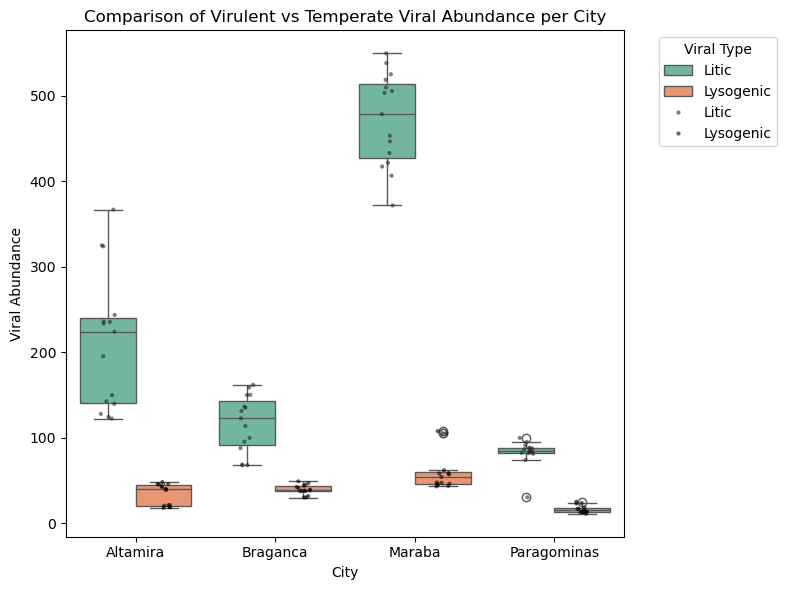

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu


# ===== Plot boxplots =====
plt.figure(figsize=(8,6))
sns.boxplot(data=merged_LM_df_rel_abund_melt, x="city", y="abundance", hue="type", palette="Set2")
sns.stripplot(data=merged_LM_df_rel_abund_melt, x="city", y="abundance", hue="type", 
              dodge=True, color="black", size=3, alpha=0.6)

# ===== Adjust legends and titles =====
plt.title("Comparison of Virulent vs Temperate Viral Abundance per City")
plt.ylabel("Viral Abundance")
plt.xlabel("City")
plt.legend(title="Viral Type", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()